In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import tda_ecg as tda

In [4]:
ecg = pd.read_csv(r"C:\CODE\Python\ecg_topology\data\raw\base\mitbih_train.csv")
ecg_target = ecg.iloc[:, -1]
ecg = ecg.iloc[:, :-1]

In [ ]:
ecg_target

class
0    72486
4     7185
2     5788
1     5000
3     5000
Name: count, dtype: int64

In [6]:
ecg.head()

,sample_0,sample_1,sample_2,sample_3,sample_4,sample_5,sample_6,sample_7,sample_8,sample_9,...,sample_177,sample_178,sample_179,sample_180,sample_181,sample_182,sample_183,sample_184,sample_185,sample_186
0,-0.977572,-0.972768,-0.968161,-0.965709,-0.966227,-0.969322,-0.974151,-0.980100,-0.986780,-0.993535,...,-0.496860,-0.512802,-0.521362,-0.522259,-0.517705,-0.511608,-0.508083,-0.509798,-0.516850,-0.526770
1,0.464128,0.431055,0.405098,0.391518,0.390767,0.398898,0.410015,0.419431,0.425920,0.431959,...,0.440905,0.394728,0.348130,0.300694,0.254350,0.213001,0.180963,0.160825,0.151771,0.149337
2,0.081839,0.116778,0.144516,0.159466,0.159550,0.146540,0.125476,0.103312,0.087072,0.082030,...,0.111813,0.117879,0.134985,0.157900,0.179685,0.193657,0.195196,0.182887,0.158828,0.128157
3,-1.433423,-1.472628,-1.503919,-1.524128,-1.532618,-1.530472,-1.519726,-1.502693,-1.481516,-1.458349,...,-1.338897,-1.309532,-1.280891,-1.258424,-1.245690,-1.243805,-1.251650,-1.266523,-1.285002,-1.303826
4,0.390901,0.376039,0.365789,0.363932,0.371141,0.384957,0.401076,0.415177,0.424342,0.427555,...,0.071662,0.052237,0.029729,0.004736,-0.019351,-0.036876,-0.041912,-0.030935,-0.004932,0.030173


<Axes: >

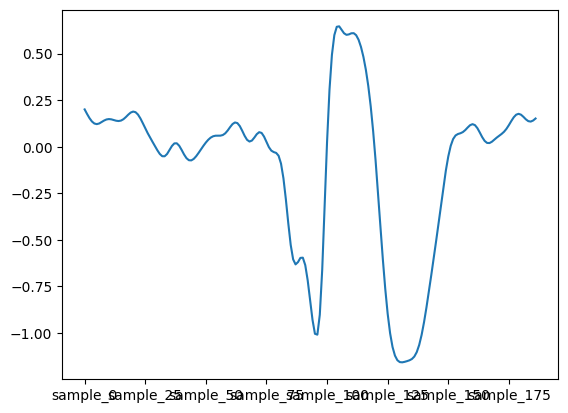

In [24]:
ecg.iloc[152].plot()

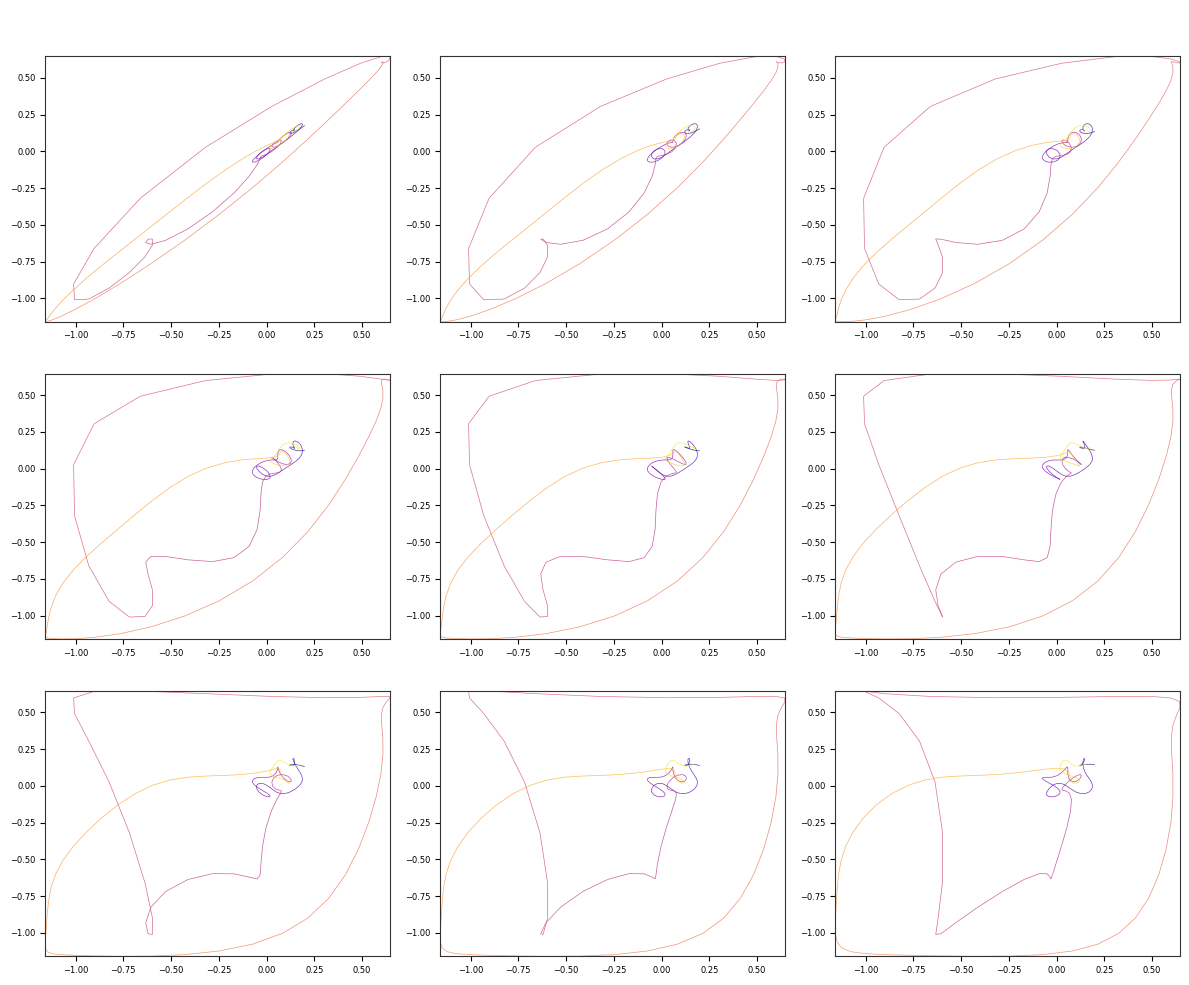

In [21]:

delays = [1, 2, 3, 4, 5, 6, 7, 8, 9]

fig, axes = plt.subplots(3, 3, figsize=(12, 10), facecolor='white')
axes = axes.flatten()

for idx, delay in enumerate(delays):
    embedded = tda.takens_embedding(ecg.iloc[152], dimension=2, delay=delay)
    x, y = embedded[:, 0], embedded[:, 1]

    ax = axes[idx]
    ax.set_facecolor('white')

    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    from matplotlib.collections import LineCollection
    norm = plt.Normalize(0, len(segments))
    lc = LineCollection(segments, cmap='plasma', norm=norm, linewidth=0.5, alpha=0.8)
    lc.set_array(np.arange(len(segments)))
    ax.add_collection(lc)

    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(y.min(), y.max())
    ax.set_title(f"τ = {delay}", color='white', fontsize=9)
    ax.tick_params(colors='black', labelsize=6)
    for spine in ax.spines.values():
        spine.set_edgecolor('#333333')


plt.suptitle("Teorema de Takens — Dimensión 2", color='white', fontsize=13)
plt.tight_layout()
plt.show()

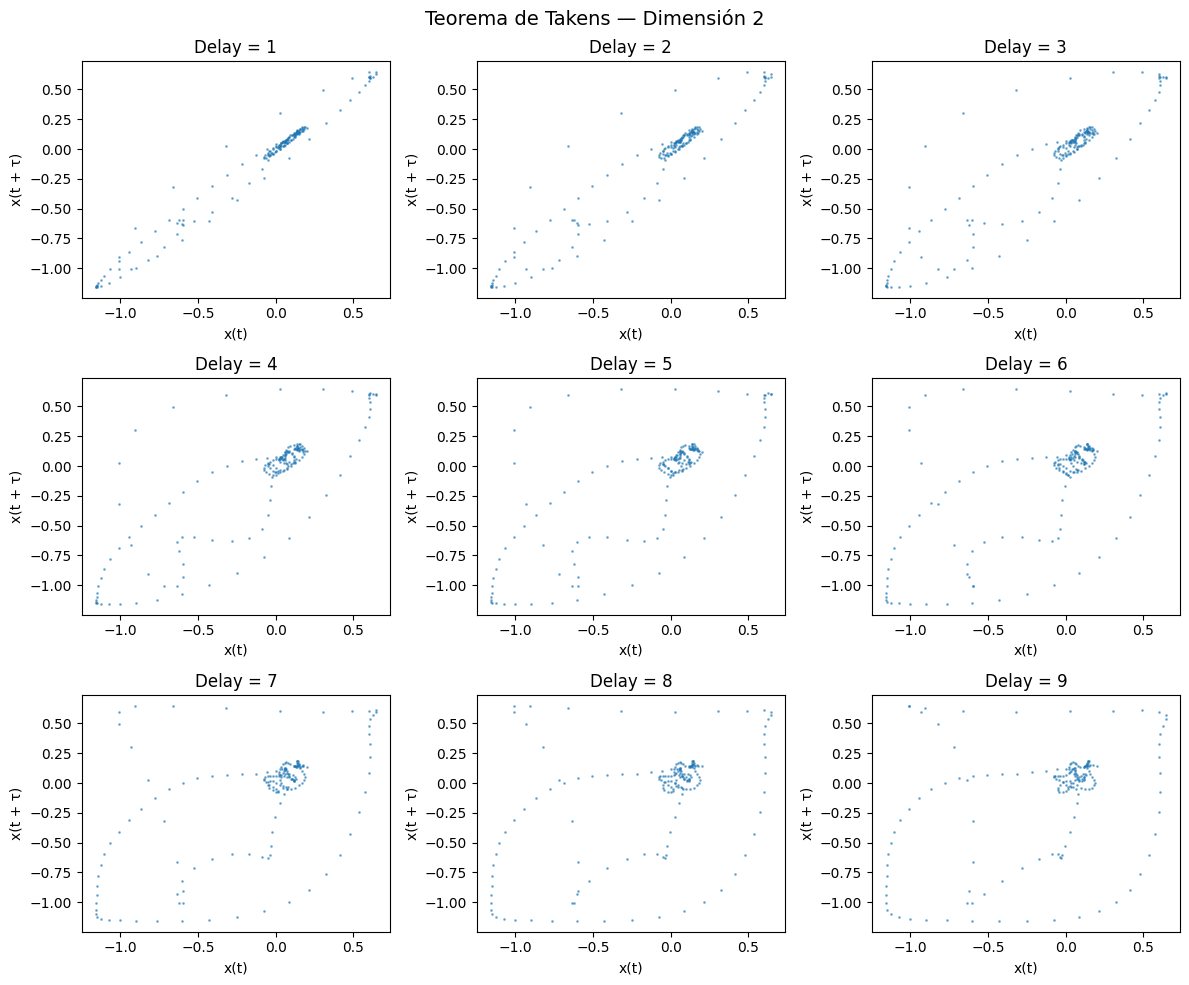

In [22]:

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

for idx, delay in enumerate(delays):
    embedded = tda.takens_embedding(ecg.iloc[152], dimension=2, delay=delay)
    axes[idx].scatter(embedded[:, 0], embedded[:, 1], s=1, alpha=0.5)
    axes[idx].set_title(f"Delay = {delay}")
    axes[idx].set_xlabel("x(t)")
    axes[idx].set_ylabel("x(t + τ)")


plt.suptitle("Teorema de Takens — Dimensión 2", fontsize=14)
plt.tight_layout()
plt.show()

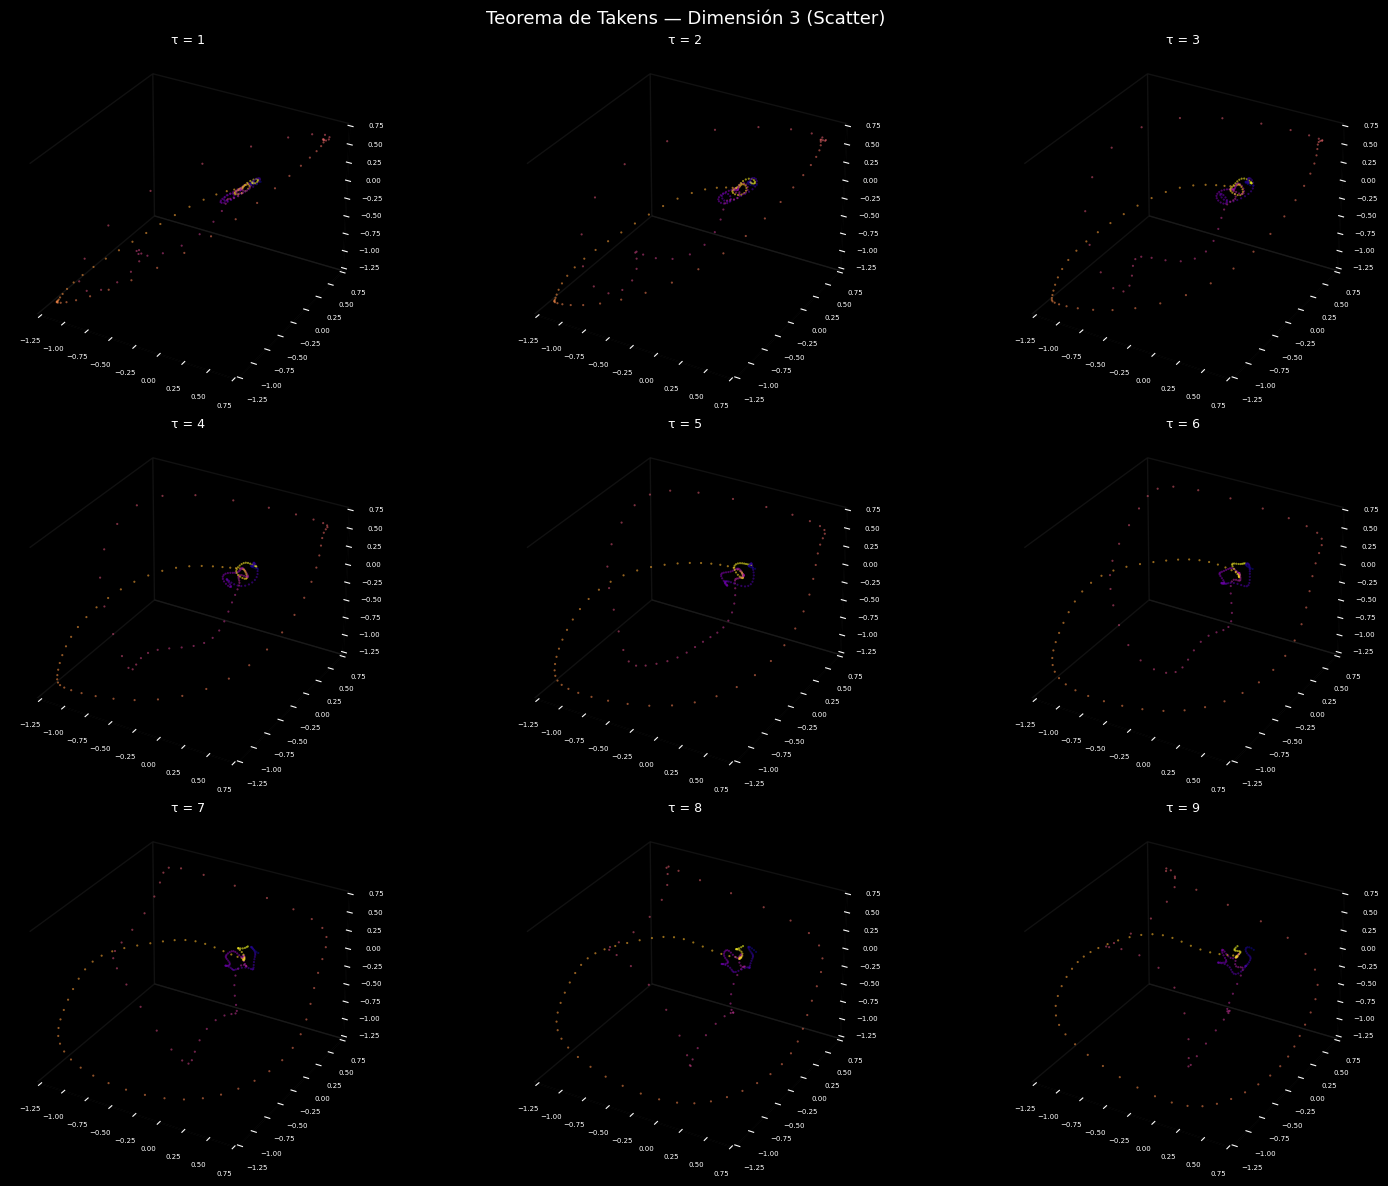

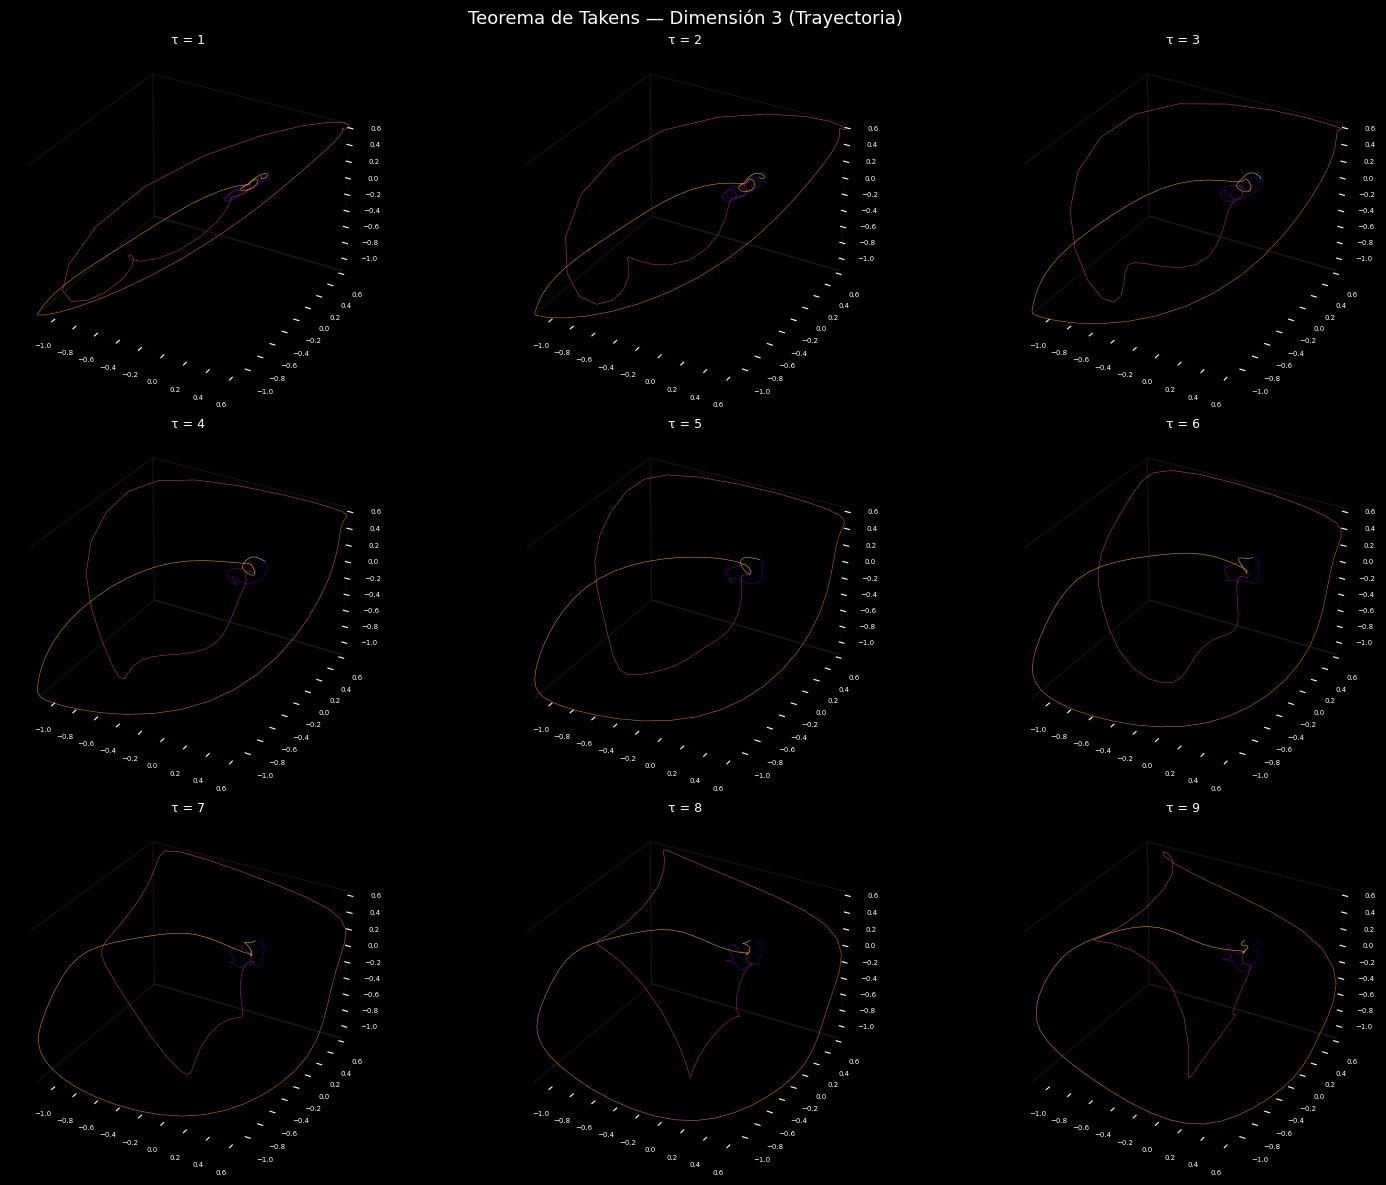

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection


for plot_type in ['scatter', 'lines']:
    fig = plt.figure(figsize=(16, 12), facecolor='black')
    fig.suptitle(
        f"Teorema de Takens — Dimensión 3 ({'Scatter' if plot_type == 'scatter' else 'Trayectoria'})",
        color='white', fontsize=13
    )

    for idx, delay in enumerate(delays):
        embedded = tda.takens_embedding(ecg.iloc[152], dimension=3, delay=delay)
        x, y, z = embedded[:, 0], embedded[:, 1], embedded[:, 2]

        ax = fig.add_subplot(3, 3, idx + 1, projection='3d')
        ax.set_facecolor('black')
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        ax.xaxis.pane.set_edgecolor('#222222')
        ax.yaxis.pane.set_edgecolor('#222222')
        ax.zaxis.pane.set_edgecolor('#222222')
        ax.grid(False)
        ax.tick_params(colors='white', labelsize=5)
        ax.xaxis.label.set_color('white')
        ax.yaxis.label.set_color('white')
        ax.zaxis.label.set_color('white')
        ax.set_title(f"τ = {delay}", color='white', fontsize=9, pad=2)

        if plot_type == 'scatter':
            t = np.linspace(0, 1, len(x))
            colors = plt.cm.plasma(t)
            ax.scatter(x, y, z, c=colors, s=0.3, alpha=0.6)

        else:  # lines
            points = np.array([x, y, z]).T.reshape(-1, 1, 3)
            segments = np.concatenate([points[:-1], points[1:]], axis=1)
            norm = plt.Normalize(0, len(segments))
            lc = Line3DCollection(segments, cmap='plasma', norm=norm,
                                  linewidth=0.4, alpha=0.85)
            lc.set_array(np.arange(len(segments)))
            ax.add_collection3d(lc)
            ax.set_xlim(x.min(), x.max())
            ax.set_ylim(y.min(), y.max())
            ax.set_zlim(z.min(), z.max())

    
    ax_last = fig.add_subplot(3, 3, 9, projection='3d')
    ax_last.set_visible(False)

    plt.tight_layout()
    plt.show()